# Intelligent Network Intrusion Detection System (NIDS)
### Dataset analysis, model training and evaluation (supporting notebook)

> **Authorized educational use only.** Run this project only on data, devices and networks you own or have
> written permission to monitor. This notebook uses a public dataset and packets simulated in memory;
> nothing is ever transmitted on a real network.

**Project structure**
```
nids_project/
├── backend/            <- ML + capture engine (pure Python, no UI)
│   ├── schema.py         feature names used everywhere
│   ├── features.py       packets -> flows -> feature vectors
│   ├── db.py              SQLite data layer
│   ├── detector.py        loads the saved model, scores flows
│   ├── capture.py         CLI: pcap replay / live capture
│   ├── capture_control.py  start/stop/status of live capture
│   ├── simulate_traffic.py  safe in-memory traffic generator
│   └── train_model.py     trains + saves the deployed model
├── frontend/
│   └── app.py            Streamlit dashboard (UI only, calls backend)
├── notebooks/
│   └── 01_EDA_and_Model_Training.ipynb   <- this file
├── data/, models/
```

This notebook **imports the backend package** for training and feature extraction rather than
redefining that logic, so the notebook, the CLI, and the dashboard can never drift out of sync.

| Part | Content |
|---|---|
| 1 | Load NSL-KDD, understand feature groups |
| 2 | Exploratory data analysis |
| 3 | Train and compare models (uses `backend.train_model`) |
| 4 | Evaluation: confusion matrix, ROC, per-attack recall, thresholds |
| 5 | Dataset shift: why a random split overstates accuracy |
| 6 | Multiclass extension (DoS / Probe / R2L / U2R) |
| 7 | Save the deployed model (calls `backend.train_model.train_and_save`) |
| 8 | End-to-end test: simulate traffic → backend pipeline → SQLite |
| 9 | Limitations, report checklist, exercises |

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from backend.schema import COLUMNS, CATEGORICAL, FEATURES_FULL, FEATURES_LIVE, ATTACK_FAMILY

print("Project root:", PROJECT_ROOT)
print(len(FEATURES_FULL), "full features |", len(FEATURES_LIVE), "live-computable features")

Project root: /home/claude/nids_project
41 full features | 13 live-computable features


## Part 1: Load the data and understand feature groups

**Dataset: NSL-KDD** (an improved KDD'99 with duplicates removed). Each row is one network *connection*
described by 41 features plus a label. We use the official split: `KDDTrain+.txt` / `KDDTest+.txt`.
The test file deliberately includes attack types absent from training.

| Group | Examples | Can a packet sniffer compute it live? |
|---|---|---|
| Basic | `duration`, `protocol_type`, `src_bytes`, `dst_bytes`, `land` | Yes |
| Content | `num_failed_logins`, `root_shell`, `hot` | No — needs payload/application-layer inspection |
| Time-window (2 s) | `count`, `srv_count`, `serror_rate`, `rerror_rate` | Yes, with a short history |
| Host-based (last 100 conns) | `dst_host_*` | Hard — needs long per-host history |

`backend/schema.py` encodes this split as `FEATURES_LIVE`, which is what the deployed model and
`backend/features.py` actually use.

In [2]:
import urllib.request

DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
for fname in ["KDDTrain+.txt", "KDDTest+.txt"]:
    path = DATA_DIR / fname
    if path.exists():
        print("found", path)
        continue
    try:
        urllib.request.urlretrieve(BASE_URL + fname, path)
        print("downloaded", path)
    except Exception as e:
        print(f"Could not download {fname}: {e}. Place it in data/ manually (e.g. from Kaggle 'NSL-KDD').")

found /home/claude/nids_project/data/KDDTrain+.txt
found /home/claude/nids_project/data/KDDTest+.txt


In [3]:
train = pd.read_csv(DATA_DIR / "KDDTrain+.txt", names=COLUMNS)
test  = pd.read_csv(DATA_DIR / "KDDTest+.txt",  names=COLUMNS)
print("train:", train.shape, "| test:", test.shape)

print("\nMissing values (train):", int(train.isna().sum().sum()))
print("Duplicate rows (train):", int(train.duplicated().sum()))
print("Attack types in train:", train.label.nunique(), "| in test:", test.label.nunique())
print("Attack types ONLY in test (unseen during training):", sorted(set(test.label) - set(train.label)))

for df in (train, test):
    df["target"] = (df["label"] != "normal").astype(int)      # 0 = normal/benign, 1 = attack/malicious
    df["family"] = df["label"].map(ATTACK_FAMILY)
    df.drop(columns=["difficulty"], inplace=True)

print("\nAttack share  train: %.1f%%   test: %.1f%%" % (100 * train.target.mean(), 100 * test.target.mean()))
train.head()

train: (125973, 43) | test: (22544, 43)

Missing values (train): 0
Duplicate rows (train): 0
Attack types in train: 23 | in test: 38


Attack types ONLY in test (unseen during training): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Attack share  train: 46.5%   test: 56.9%


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,target,family
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0,normal


## Part 2: Exploratory data analysis

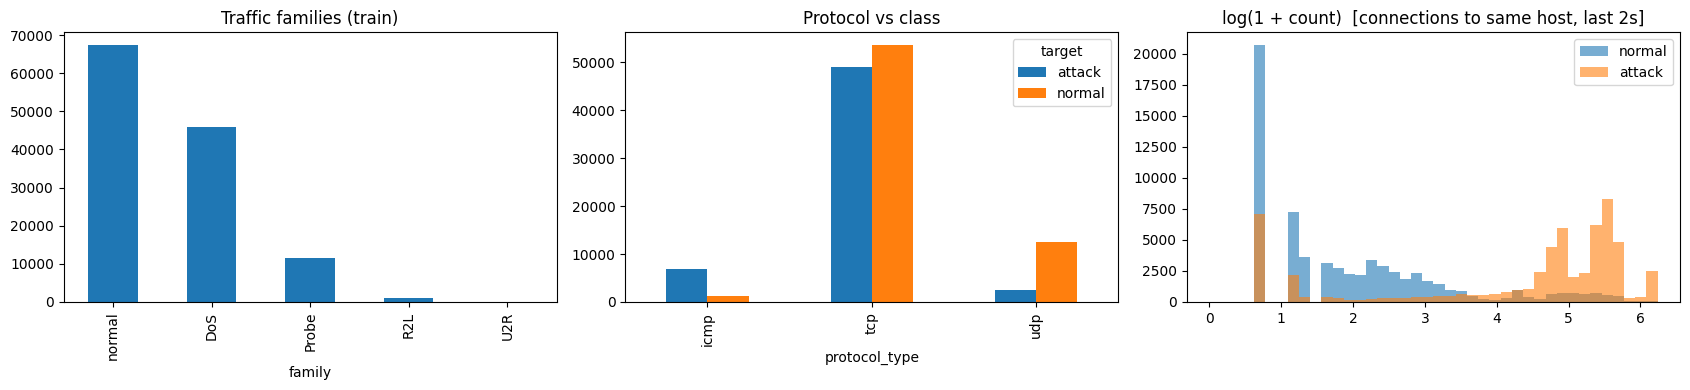

,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,rerror_rate,same_srv_rate
target,,,,,,,,
0,168.59,13133.28,4329.69,22.52,27.69,0.01,0.04,0.97
1,423.32,82820.14,37524.48,154.85,27.80,0.60,0.21,0.31


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

train.family.value_counts().plot.bar(ax=ax[0], color="tab:blue")
ax[0].set_title("Traffic families (train)")

pd.crosstab(train.protocol_type, train.target.map({0: "normal", 1: "attack"})).plot.bar(ax=ax[1])
ax[1].set_title("Protocol vs class")

for t, name in [(0, "normal"), (1, "attack")]:
    ax[2].hist(np.log1p(train.loc[train.target == t, "count"]), bins=40, alpha=.6, label=name)
ax[2].set_title("log(1 + count)  [connections to same host, last 2s]")
ax[2].legend()
plt.tight_layout(); plt.show()

train.groupby("target")[["duration", "src_bytes", "dst_bytes", "count", "srv_count",
                         "serror_rate", "rerror_rate", "same_srv_rate"]].mean().round(2)

**Observations for the report**

- Attack connections have much higher `count` and `serror_rate`: many connections to one host in a short
  window, mostly unanswered. This is the connection-level signature of a SYN flood or scan — exactly what
  `backend/features.py` computes from live packets.
- Classes are roughly balanced here (~53/47 normal/attack). Real networks are overwhelmingly benign, so
  accuracy alone would be misleading there.
- U2R and R2L attacks hide inside payload content rather than volume, so they look like normal traffic at
  connection level — expect them to be the hardest to detect (see Part 6).

## Part 3: Train and compare models

A scikit-learn `Pipeline` bundles preprocessing (scaling + one-hot encoding) with the model, so the
scaler/encoder are fit on training data only (no leakage) and one saved object does both preprocessing
and prediction later. `backend/train_model.py` defines `make_pipeline`; we reuse it here instead of
redefining it, so training stays identical whether run from this notebook or from the command line.

In [5]:
from backend.train_model import make_pipeline, evaluate, RANDOM_STATE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X_train, y_train = train[FEATURES_FULL], train.target
X_test,  y_test  = test[FEATURES_FULL],  test.target

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=15, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
}

fitted, rows = {}, []
for name, model in candidate_models.items():
    fitted[name] = make_pipeline(model, FEATURES_FULL).fit(X_train, y_train)
    rows.append({"model": name, **evaluate(fitted[name], X_test, y_test)})

results = pd.DataFrame(rows).set_index("model").round(4)
results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.7537,0.9174,0.6234,0.7424,0.7929
Decision Tree,0.7833,0.9584,0.6474,0.7728,0.7236
Random Forest,0.7669,0.9672,0.6113,0.7491,0.9594


Test accuracy is around 75-78%, far below the ~99% often quoted for NSL-KDD. Part 5 explains why: the
official test set contains attack types never seen in training. Read the columns this way: **precision is
high** (alerts are usually correct) but **recall is lower** (some attacks are missed) — mostly the unseen ones.

## Part 4: Evaluation in depth

Best by F1: Decision Tree 

              precision    recall  f1-score   support

      normal       0.67      0.96      0.79      9711
      attack       0.96      0.65      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.78     22544



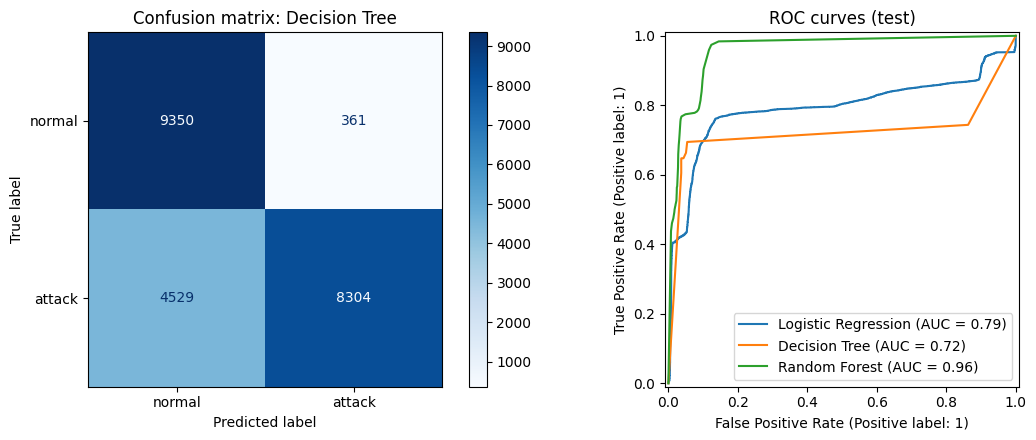

In [6]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve, precision_score, recall_score)

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

best_name = results["f1"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
print("Best by F1:", best_name, "\n")
print(classification_report(y_test, pred, target_names=["normal", "attack"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["normal", "attack"], ax=ax[0], cmap="Blues")
ax[0].set_title(f"Confusion matrix: {best_name}")
for name, p in fitted.items():
    RocCurveDisplay.from_estimator(p, X_test, y_test, ax=ax[1], name=name)
ax[1].set_title("ROC curves (test)")
plt.tight_layout()
plt.savefig(MODELS_DIR / "confusion_and_roc_full.png", dpi=130)
plt.show()

In [7]:
# Which attacks do we miss?  (recall per attack type on the official test set)
tmp = test.assign(pred=pred)
per_attack = (tmp[tmp.target == 1].groupby("label")
              .apply(lambda g: pd.Series({"n": len(g), "detected_%": round(100 * (g.pred == 1).mean(), 1)})))
per_attack.sort_values("n", ascending=False).head(15)

,n,detected_%
label,,
neptune,4657.0,100.0
guess_passwd,1231.0,0.0
mscan,996.0,59.6
warezmaster,944.0,24.4
apache2,737.0,45.3
satan,735.0,99.9
processtable,685.0,23.6
smurf,665.0,100.0
back,359.0,38.7


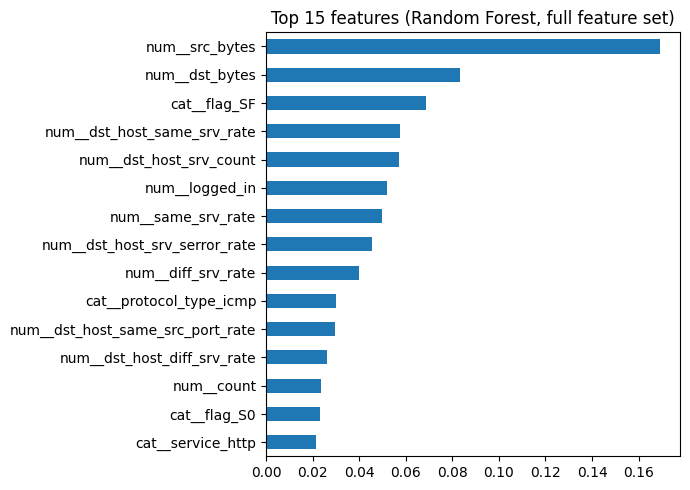

In [8]:
rf_full = fitted["Random Forest"]
feature_names = rf_full.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_full.named_steps["model"].feature_importances_, index=feature_names).sort_values(ascending=False)
importances.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="Top 15 features (Random Forest, full feature set)")
plt.tight_layout()
plt.savefig(MODELS_DIR / "feature_importance_full.png", dpi=130)
plt.show()

### Threshold tuning: the false-negative vs alert-fatigue trade-off

A classifier outputs P(attack); we alert when P ≥ *threshold*. Lower threshold → more attacks caught
(recall ↑) but more false alarms (precision ↓). We use the Random Forest, since a single Decision Tree
gives almost only 0/1 probabilities and barely moves with the threshold.

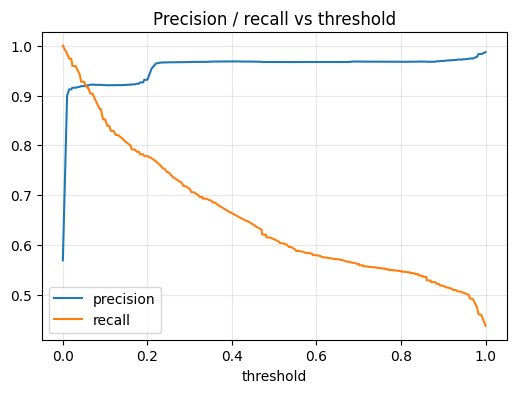

,threshold,precision,recall
0,0.1,0.921,0.852
1,0.2,0.932,0.778
2,0.3,0.967,0.713
3,0.5,0.967,0.611
4,0.7,0.968,0.562


In [9]:
proba = rf_full.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, proba)

plt.figure(figsize=(6, 4))
plt.plot(thresholds, precisions[:-1], label="precision")
plt.plot(thresholds, recalls[:-1], label="recall")
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("Precision / recall vs threshold")
plt.show()

pd.DataFrame([
    {"threshold": t, "precision": precision_score(y_test, proba >= t), "recall": recall_score(y_test, proba >= t)}
    for t in (0.1, 0.2, 0.3, 0.5, 0.7)
]).round(3)

## Part 5: Why a random split overstates accuracy

Many tutorials split `KDDTrain+` randomly into train/validation and report ~99%. We reproduce that and
compare it with the official test set. The gap is **dataset shift**: tomorrow's attacks differ from
yesterday's, and a model trained only on known patterns struggles with new ones.

In [10]:
from sklearn.model_selection import train_test_split

X_a, X_b, y_a, y_b = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
rf_random_split = make_pipeline(
    RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE), FEATURES_FULL
).fit(X_a, y_a)

pd.DataFrame({
    "Random split of train (in-distribution)": evaluate(rf_random_split, X_b, y_b),
    "Official KDDTest+ (new attack types)":     evaluate(rf_full, X_test, y_test),
}).T.round(4)

,accuracy,precision,recall,f1,roc_auc
Random split of train (in-distribution),0.9991,0.9995,0.9986,0.9991,1.0000
Official KDDTest+ (new attack types),0.7669,0.9672,0.6113,0.7491,0.9594


**Report point:** the ~99% figure measures memorization of known attack patterns. The official-test score is the more honest estimate of behavior against unfamiliar attacks — which is what a real deployment faces.

## Part 6: Extension — multiclass attack-family classification

Instead of normal-vs-attack, predict the family: **normal, DoS, Probe, R2L, U2R** (mapping defined in
`backend.schema.ATTACK_FAMILY`). This uses the full 41-feature set to show what's possible with content
features, which the live deployment (Part 7) does not have access to.

              precision    recall  f1-score   support

         DoS       0.96      0.76      0.85      7458
       Probe       0.85      0.60      0.70      2421
         R2L       0.81      0.01      0.01      2754
         U2R       0.60      0.01      0.03       200
      normal       0.63      0.97      0.77      9711

    accuracy                           0.74     22544
   macro avg       0.77      0.47      0.47     22544
weighted avg       0.79      0.74      0.69     22544



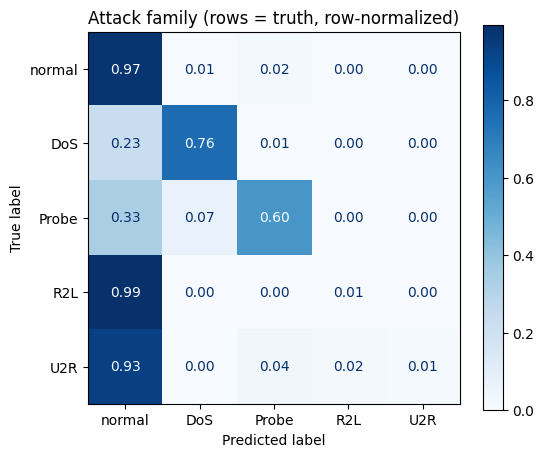

In [11]:
rf_multiclass = make_pipeline(
    RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced_subsample", random_state=RANDOM_STATE),
    FEATURES_FULL,
).fit(X_train, train.family)

multiclass_pred = rf_multiclass.predict(X_test)
print(classification_report(test.family, multiclass_pred, zero_division=0))

family_order = ["normal", "DoS", "Probe", "R2L", "U2R"]
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(test.family, multiclass_pred, labels=family_order, normalize="true",
                                        ax=ax, cmap="Blues", values_format=".2f")
ax.set_title("Attack family (rows = truth, row-normalized)")
plt.show()

Expect DoS and Probe to be detected well, and R2L/U2R poorly — the classic weakness of connection-level features against content-based attacks. Discuss this limitation in your report.

## Part 7: Train and save the deployed model

The deployed model can only use `FEATURES_LIVE` (13 features `backend/features.py` can compute from raw
packets). `backend/train_model.train_and_save()` is the single place that trains and persists this model —
calling it here keeps the notebook and the `python backend/train_model.py` CLI identical.

In [12]:
from backend.train_model import train_and_save, DEFAULT_THRESHOLD

live_metrics = train_and_save(threshold=DEFAULT_THRESHOLD)
print(f"Deployed model saved. Threshold={DEFAULT_THRESHOLD}")
print({k: round(v, 4) for k, v in live_metrics.items()})

# Compare against the full-feature model, to see the cost of restricting to live-computable features
comparison = pd.DataFrame({
    "Full model (41 features, threshold 0.5)": evaluate(rf_full, X_test, y_test),
    f"Deployed model ({len(FEATURES_LIVE)} features, threshold {DEFAULT_THRESHOLD})": live_metrics,
}).T.round(4)
comparison

Deployed model saved. Threshold=0.3
{'accuracy': 0.8422, 'precision': 0.9626, 'recall': 0.752, 'f1': 0.8443, 'roc_auc': 0.9686}


,accuracy,precision,recall,f1,roc_auc
"Full model (41 features, threshold 0.5)",0.7669,0.9672,0.6113,0.7491,0.9594
"Deployed model (13 features, threshold 0.3)",0.8422,0.9626,0.7520,0.8443,0.9686


In [13]:
# Sanity check: reload exactly what capture.py / app.py will load, and predict a few unseen rows
import joblib
from backend.detector import Detector

loaded = Detector()     # reads models/nids_pipeline.joblib + models/feature_list.json
sample = test[FEATURES_LIVE].sample(5, random_state=1)
pd.DataFrame({
    "P(malicious)": loaded.pipeline.predict_proba(sample)[:, 1].round(3),
    "actual_label": test.loc[sample.index, "label"],
})

,P(malicious),actual_label
13003,0.033,guess_passwd
8908,1.000,neptune
11599,0.001,normal
20226,0.001,normal
11643,0.102,guess_passwd


## Part 8: End-to-end test with simulated traffic

To test the **whole backend pipeline** (packets → flows → features → model → SQLite) without touching any
real network, `backend/simulate_traffic.py` crafts packets in memory with Scapy and writes them to a
`.pcap` file. Nothing is transmitted anywhere. It contains normal sessions plus a SYN flood, a port scan,
and a ping sweep, all from one labeled "attacker" address, used here only as ground truth for this test.

In [14]:
from backend import simulate_traffic, capture, db
from scapy.utils import wrpcap

packets = simulate_traffic.build()
wrpcap(str(simulate_traffic.OUTPUT_PATH), packets)
print(f"{len(packets)} simulated packets written to {simulate_traffic.OUTPUT_PATH}")

3245 simulated packets written to /home/claude/nids_project/data/sim_traffic.pcap


In [15]:
test_db_path = PROJECT_ROOT / "nids_test.db"
if test_db_path.exists():
    test_db_path.unlink()

summary = capture.run_pcap(simulate_traffic.OUTPUT_PATH, db_path=test_db_path)
print(summary)

history = db.fetch(db_path=test_db_path, limit=10000)
history.head(10)

{'packets': 3245, 'flows': 726, 'malicious': 504, 'benign': 222}


,id,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,prediction,confidence
0,726,2026-10-03 06:17:06,192.168.56.104,192.168.56.1,33751,53,udp,benign,0.0009
1,725,2026-10-03 06:17:05,192.168.56.102,192.168.56.20,33830,80,tcp,benign,0.0570
2,724,2026-10-03 06:17:04,192.168.56.101,192.168.56.20,53550,443,tcp,benign,0.0475
3,723,2026-10-03 06:17:02,192.168.56.104,192.168.56.20,53486,443,tcp,benign,0.0171
4,722,2026-10-03 06:16:57,192.168.56.104,192.168.56.21,56316,22,tcp,malicious,0.8563
5,721,2026-10-03 06:16:57,192.168.56.103,192.168.56.20,43896,80,tcp,benign,0.0131
6,720,2026-10-03 06:16:52,192.168.56.103,192.168.56.20,36594,443,tcp,benign,0.0356
7,719,2026-10-03 06:16:51,192.168.56.104,192.168.56.20,45826,80,tcp,benign,0.0214
8,718,2026-10-03 06:16:51,192.168.56.21,192.168.56.104,22,56316,tcp,benign,0.0150
9,717,2026-10-03 06:16:48,192.168.56.103,192.168.56.1,56668,53,udp,benign,0.0050


In [16]:
# Ground truth for this demo: anything sent by the simulated attacker is an attack
history["truth"] = np.where(history.src_ip == simulate_traffic.ATTACKER, "malicious", "benign")

print(pd.crosstab(history.truth, history.prediction, rownames=["truth"], colnames=["predicted"]))
print()
print(classification_report(history.truth, history.prediction, zero_division=0))

def scenario(row):
    if row.truth == "benign":
        return "normal traffic"
    if row.protocol == "icmp":
        return "ping sweep"
    if row.protocol == "tcp" and row.dst_port == 80 and row.dst_ip == simulate_traffic.WEB_SERVER:
        return "SYN flood"
    return "port scan"

history["scenario"] = history.apply(scenario, axis=1)
history.groupby("scenario").agg(flows=("id", "count"),
                                flagged_malicious=("prediction", lambda s: round((s == "malicious").mean(), 3)))

predicted  benign  malicious
truth                       
benign        121          5
malicious     101        499

              precision    recall  f1-score   support

      benign       0.55      0.96      0.70       126
   malicious       0.99      0.83      0.90       600

    accuracy                           0.85       726
   macro avg       0.77      0.90      0.80       726
weighted avg       0.91      0.85      0.87       726



,flows,flagged_malicious
scenario,,
SYN flood,300,0.997
normal traffic,126,0.040
ping sweep,100,0.000
port scan,200,1.000


**How to read this demo honestly (include this in your report)**

- The model was trained on 1998-era lab data (NSL-KDD); the simulated packets are modern and idealized.
  Expect some misclassified flows, especially near the decision boundary.
- Good results here show the **pipeline** is consistent end to end (same 13 features computed the same way
  in training and in `backend/features.py`). They do **not** prove real-world accuracy.
- For stronger evidence, retrain on a modern flow dataset such as CIC-IDS2017 and test with real,
  authorized scans between two VMs you own on an isolated host-only network (never on a college/public network).

## Part 9: Limitations, report checklist, exercises

### Limitations to state clearly
1. **Dataset age.** NSL-KDD is derived from 1998 simulated traffic; modern encrypted traffic looks different.
2. **Unseen attacks.** Supervised models detect known patterns — see the validation-vs-test gap in Part 5.
3. **Feature approximations.** `wrong_fragment` counts IP fragments; the 2-second window is computed from
   one sensor's view of one network segment, not the original testbed.
4. **Idealized simulation.** The Part 8 pcap demonstrates pipeline consistency, not real-world accuracy.
5. **Connection-level features miss content attacks** (R2L/U2R hide inside payloads).
6. **Evasion.** An attacker who slows a scan below the 2-second window can defeat window-count features.

### Report checklist
- Problem statement, IDS/IPS/NIDS concepts, architecture diagram (top of this notebook)
- Dataset description, class balance, feature groups
- Preprocessing + pipeline design (leakage prevention)
- Model comparison, confusion matrix, ROC, per-attack recall
- Threshold trade-off discussion
- Random-split vs official-test comparison (dataset shift)
- Live feature engineering and its cost (Part 7 comparison table)
- SQLite schema, dashboard screenshots (run `streamlit run frontend/app.py`)
- Ethics: authorized-use policy, isolated-VM testing only
- Limitations and future work

### Exercises
1. Add `HistGradientBoostingClassifier` to the model comparison in Part 3.
2. Pick the alert threshold on a held-out validation split (not the test set) and justify it.
3. Add `service` (map `dst_port` to a service name) and `flag` (from TCP state) to `FEATURES_LIVE`, then retrain.
4. Port `backend/features.py` to CIC-IDS2017-style flow features — only `schema.py`, `features.py`, and
   `train_model.py` need to change; `detector.py`, `db.py`, `capture.py` and `app.py` stay the same.
5. Add an email/log-file alert in `backend/capture.py` when P(malicious) > 0.9.
6. Train an `IsolationForest` on normal traffic only (unsupervised) and compare recall on unseen attacks.

### Running the full project (Windows)
```powershell
python -m venv venv
venv\Scripts\activate
pip install -r requirements.txt
python backend/train_model.py                 # trains and saves the model (also done in Part 7 above)
python backend/simulate_traffic.py            # writes data/sim_traffic.pcap
python backend/capture.py --pcap data/sim_traffic.pcap   # test the backend end to end
streamlit run frontend/app.py                 # launch the dashboard
```
Live capture (separate Administrator terminal, Npcap installed):
```powershell
python backend/capture.py --list-ifaces
python backend/capture.py --live --iface "Wi-Fi" --authorized
```